In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/Project2_SolarPV")

data = {
    h: pd.read_csv(
        folder / f"ds_h{h}_split.csv",
        parse_dates=["DATE_TIME", "TARGET_TIME"]
    )
    for h in [1, 2, 4]
}

for h, df in data.items():
    print(f"\nHorizon: {h * 15} minutes")
    print("Shape:", df.shape)
    print("Rows in each split:")
    print(df["SPLIT"].value_counts())
    display(df.head(3))

Mounted at /content/drive

Horizon: 15 minutes
Shape: (3111, 13)
Rows in each split:
SPLIT
train    2159
val       479
test      473
Name: count, dtype: int64


,DATE_TIME,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,AC_POWER_lag1,AC_POWER_lag2,AC_POWER_lag3,TARGET_TIME,TARGET,hour_sin,hour_cos,SPLIT
0,2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0,0.0,0.0,0.0,2020-05-15 01:00:00,0.0,0.195090,0.980785,train
1,2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0,0.0,0.0,0.0,2020-05-15 01:15:00,0.0,0.258819,0.965926,train
2,2020-05-15 01:15:00,0.0,24.536092,21.968571,0.0,0.0,0.0,0.0,2020-05-15 01:30:00,0.0,0.321439,0.946930,train



Horizon: 30 minutes
Shape: (3101, 13)
Rows in each split:
SPLIT
train    2152
val       478
test      471
Name: count, dtype: int64


,DATE_TIME,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,AC_POWER_lag1,AC_POWER_lag2,AC_POWER_lag3,TARGET_TIME,TARGET,hour_sin,hour_cos,SPLIT
0,2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0,0.0,0.0,0.0,2020-05-15 01:15:00,0.0,0.195090,0.980785,train
1,2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0,0.0,0.0,0.0,2020-05-15 01:30:00,0.0,0.258819,0.965926,train
2,2020-05-15 01:15:00,0.0,24.536092,21.968571,0.0,0.0,0.0,0.0,2020-05-15 01:45:00,0.0,0.321439,0.946930,train



Horizon: 60 minutes
Shape: (3084, 13)
Rows in each split:
SPLIT
train    2139
val       476
test      469
Name: count, dtype: int64


,DATE_TIME,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,AC_POWER_lag1,AC_POWER_lag2,AC_POWER_lag3,TARGET_TIME,TARGET,hour_sin,hour_cos,SPLIT
0,2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0,0.0,0.0,0.0,2020-05-15 01:45:00,0.0,0.195090,0.980785,train
1,2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0,0.0,0.0,0.0,2020-05-15 02:00:00,0.0,0.258819,0.965926,train
2,2020-05-15 01:15:00,0.0,24.536092,21.968571,0.0,0.0,0.0,0.0,2020-05-15 02:15:00,0.0,0.321439,0.946930,train


the four comparisons

* A: weather only
* A+time: weather and time of day
* B: weather and recent power history
* B+time: weather, recent power history, and time of dayList item



In [2]:
weather_features = [
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
]

time_features = ["hour_sin", "hour_cos"]

power_history_features = [
    "AC_POWER_lag1",
    "AC_POWER_lag2",
    "AC_POWER_lag3",
]

feature_sets = {
    "A_weather": weather_features,
    "A_time": weather_features + time_features,
    "B_history": weather_features + power_history_features,
    "B_time": weather_features + power_history_features + time_features,
}

for name, features in feature_sets.items():
    print(f"{name}: {features}")

# Confirm that every feature exists in every horizon dataset.
for h, df in data.items():
    missing = [
        feature
        for features in feature_sets.values()
        for feature in features
        if feature not in df.columns
    ]
    if missing:
        raise ValueError(f"Horizon {h}: missing columns {sorted(set(missing))}")

print("\nAll required feature columns are present.")

A_weather: ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']
A_time: ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'hour_sin', 'hour_cos']
B_history: ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'AC_POWER_lag1', 'AC_POWER_lag2', 'AC_POWER_lag3']
B_time: ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'AC_POWER_lag1', 'AC_POWER_lag2', 'AC_POWER_lag3', 'hour_sin', 'hour_cos']

All required feature columns are present.


train three model types for each feature set and forecast horizon. This cell fits each model using training rows only, then measures validation performance. The test set stays untouched for the final evaluation.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def make_models():
    return {
        "LinearRegression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        "RandomForest": RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),
        "GradientBoosting": GradientBoostingRegressor(
            random_state=42
        ),
    }

validation_rows = []
trained_models = {}

for h, df in data.items():
    train_df = df[df["SPLIT"] == "train"]
    val_df = df[df["SPLIT"] == "val"]

    y_train = train_df["TARGET"]
    y_val = val_df["TARGET"]

    for feature_name, features in feature_sets.items():
        X_train = train_df[features]
        X_val = val_df[features]

        for model_name, model in make_models().items():
            model.fit(X_train, y_train)
            val_pred = model.predict(X_val)

            validation_rows.append({
                "horizon_steps": h,
                "horizon_minutes": h * 15,
                "feature_set": feature_name,
                "model": model_name,
                "MAE": mean_absolute_error(y_val, val_pred),
                "RMSE": mean_squared_error(y_val, val_pred) ** 0.5,
                "R2": r2_score(y_val, val_pred),
            })

            # Keep fitted model so we can evaluate selected models on test later.
            trained_models[(h, feature_name, model_name)] = model

validation_results = pd.DataFrame(validation_rows)
validation_results = validation_results.sort_values(
    ["horizon_steps", "feature_set", "MAE"]
).reset_index(drop=True)

display(validation_results.round(3))

,horizon_steps,horizon_minutes,feature_set,model,MAE,RMSE,R2
0,1,15,A_time,GradientBoosting,957.035,1871.382,0.947
1,1,15,A_time,RandomForest,1019.791,2014.585,0.938
2,1,15,A_time,LinearRegression,1382.559,2063.391,0.935
3,1,15,A_weather,RandomForest,1026.444,2061.352,0.935
4,1,15,A_weather,GradientBoosting,1032.849,1964.579,0.941
5,1,15,A_weather,LinearRegression,1396.173,2217.391,0.925
6,1,15,B_history,RandomForest,961.130,1943.708,0.942
7,1,15,B_history,GradientBoosting,987.088,1912.803,0.944
8,1,15,B_history,LinearRegression,1386.934,2092.474,0.933
9,1,15,B_time,GradientBoosting,962.098,1915.488,0.944


For each horizon and feature set, choosing the model with the lowest validation MAE.

In [4]:
best_by_feature_set = (
    validation_results
    .sort_values("MAE")
    .groupby(["horizon_steps", "feature_set"], as_index=False)
    .first()
)

display(best_by_feature_set.round(3))

,horizon_steps,feature_set,horizon_minutes,model,MAE,RMSE,R2
0,1,A_time,15,GradientBoosting,957.035,1871.382,0.947
1,1,A_weather,15,RandomForest,1026.444,2061.352,0.935
2,1,B_history,15,RandomForest,961.130,1943.708,0.942
3,1,B_time,15,GradientBoosting,962.098,1915.488,0.944
4,2,A_time,30,GradientBoosting,1165.033,2265.659,0.922
5,2,A_weather,30,RandomForest,1288.471,2528.573,0.903
6,2,B_history,30,RandomForest,1275.676,2479.607,0.906
7,2,B_time,30,GradientBoosting,1180.094,2336.944,0.917
8,4,A_time,60,GradientBoosting,1286.321,2453.865,0.909
9,4,A_weather,60,RandomForest,1560.171,2846.372,0.877


evaluating the selected models on the test set, which hasn’t been used for training or model selection. This cell selects the lowest validation-MAE model for each feature set, refits it using the combined training and validation rows, then calculates test metrics. Daytime is defined by the target timestamp, from 06:00 up to (but not including) 18:00.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_rows = []
test_predictions = {}

for _, choice in best_by_feature_set.iterrows():
    h = int(choice["horizon_steps"])
    feature_name = choice["feature_set"]
    model_name = choice["model"]
    features = feature_sets[feature_name]

    df = data[h]
    train_val_df = df[df["SPLIT"].isin(["train", "val"])]
    test_df = df[df["SPLIT"] == "test"]

    # Refit the chosen model on train + validation data.
    model = make_models()[model_name]
    model.fit(train_val_df[features], train_val_df["TARGET"])

    y_test = test_df["TARGET"]
    predictions = model.predict(test_df[features])

    # Daytime at the forecast target time: 06:00–17:59.
    target_hour = test_df["TARGET_TIME"].dt.hour
    daytime_mask = (target_hour >= 6) & (target_hour < 18)

    for period, mask in [
        ("all_rows", pd.Series(True, index=test_df.index)),
        ("daytime", daytime_mask),
    ]:
        actual = y_test.loc[mask]
        predicted = predictions[mask.to_numpy()]

        test_rows.append({
            "horizon_minutes": h * 15,
            "feature_set": feature_name,
            "model": model_name,
            "period": period,
            "n_rows": len(actual),
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": mean_squared_error(actual, predicted) ** 0.5,
            "R2": r2_score(actual, predicted),
        })

    test_predictions[(h, feature_name)] = (
        test_df["DATE_TIME"].reset_index(drop=True),
        test_df["TARGET_TIME"].reset_index(drop=True),
        y_test.reset_index(drop=True),
        pd.Series(predictions),
    )

test_results = pd.DataFrame(test_rows)
display(test_results.round(3))

,horizon_minutes,feature_set,model,period,n_rows,MAE,RMSE,R2
0,15,A_time,GradientBoosting,all_rows,473,1102.774,2198.628,0.929
1,15,A_time,GradientBoosting,daytime,234,2183.084,3124.997,0.822
2,15,A_weather,RandomForest,all_rows,473,1152.100,2313.897,0.921
3,15,A_weather,RandomForest,daytime,234,2304.626,3286.643,0.803
4,15,B_history,RandomForest,all_rows,473,1140.145,2312.243,0.921
5,15,B_history,RandomForest,daytime,234,2282.896,3285.018,0.803
6,15,B_time,GradientBoosting,all_rows,473,1065.290,2164.125,0.931
7,15,B_time,GradientBoosting,daytime,234,2115.511,3076.299,0.828
8,30,A_time,GradientBoosting,all_rows,471,1320.010,2583.078,0.902
9,30,A_time,GradientBoosting,daytime,233,2621.492,3671.769,0.755


save the results

In [6]:
test_results.to_csv(folder / "results_selected_test.csv", index=False)
print("Saved:", folder / "results_selected_test.csv")

Saved: /content/drive/MyDrive/Project2_SolarPV/results_selected_test.csv


Next, comparing the selected models against three no-training baselines: persistence, same time yesterday, and smart persistence. The smart baseline estimates the daily power profile from training and validation data, then carries the current clear-sky index forward.

In [7]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_rows = []

for h, df in data.items():
    test_df = df[df["SPLIT"] == "test"].copy()

    # Historical plant power, indexed by its timestamp.
    power_lookup = df.set_index("DATE_TIME")["AC_POWER"]

    # Baseline 1: predict that power stays at its current value.
    test_df["pred_persistence"] = test_df["AC_POWER"]

    # Baseline 2: predict the power from the same target time yesterday.
    yesterday_time = test_df["TARGET_TIME"] - pd.Timedelta(days=1)
    test_df["pred_yesterday"] = yesterday_time.map(power_lookup)

    # Estimate the typical high-power envelope by time of day, using only
    # training and validation data.
    train_val = df[df["SPLIT"].isin(["train", "val"])].copy()
    train_val["minute_of_day"] = (
        train_val["DATE_TIME"].dt.hour * 60
        + train_val["DATE_TIME"].dt.minute
    )
    envelope = train_val.groupby("minute_of_day")["AC_POWER"].quantile(0.95)

    current_minute = (
        test_df["DATE_TIME"].dt.hour * 60
        + test_df["DATE_TIME"].dt.minute
    )
    target_minute = (
        test_df["TARGET_TIME"].dt.hour * 60
        + test_df["TARGET_TIME"].dt.minute
    )

    current_envelope = current_minute.map(envelope)
    target_envelope = target_minute.map(envelope)

    # Current clear-sky index, carried forward to the target time.
    clear_sky_index = (
        test_df["AC_POWER"] / current_envelope.replace(0, np.nan)
    ).clip(lower=0, upper=1.5)

    test_df["pred_smart"] = clear_sky_index * target_envelope

    # Score each baseline on all rows and daytime target rows.
    daytime = (
        (test_df["TARGET_TIME"].dt.hour >= 6)
        & (test_df["TARGET_TIME"].dt.hour < 18)
    )

    for baseline_name, prediction_column in [
        ("Persistence", "pred_persistence"),
        ("Same time yesterday", "pred_yesterday"),
        ("Smart persistence", "pred_smart"),
    ]:
        for period, period_mask in [
            ("all_rows", pd.Series(True, index=test_df.index)),
            ("daytime", daytime),
        ]:
            valid = (
                period_mask
                & test_df["TARGET"].notna()
                & test_df[prediction_column].notna()
            )

            actual = test_df.loc[valid, "TARGET"]
            predicted = test_df.loc[valid, prediction_column]

            baseline_rows.append({
                "horizon_minutes": h * 15,
                "baseline": baseline_name,
                "period": period,
                "n_rows": len(actual),
                "MAE": mean_absolute_error(actual, predicted),
                "RMSE": mean_squared_error(actual, predicted) ** 0.5,
                "R2": r2_score(actual, predicted),
            })

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(3))

,horizon_minutes,baseline,period,n_rows,MAE,RMSE,R2
0,15,Persistence,all_rows,473,1206.363,2321.379,0.921
1,15,Persistence,daytime,234,2395.227,3295.760,0.802
2,15,Same time yesterday,all_rows,472,1980.157,3837.892,0.783
3,15,Same time yesterday,daytime,234,3983.165,5450.428,0.459
4,15,Smart persistence,all_rows,249,2148.869,3193.032,0.830
5,15,Smart persistence,daytime,229,2330.876,3329.368,0.789
6,30,Persistence,all_rows,471,1775.827,3156.084,0.854
7,30,Persistence,daytime,233,3486.617,4472.088,0.637
8,30,Same time yesterday,all_rows,469,1991.671,3850.066,0.783
9,30,Same time yesterday,daytime,233,3997.940,5461.997,0.458


Save the baseline scores

In [8]:
baseline_results.to_csv(folder / "results_baselines.csv", index=False)
print("Saved:", folder / "results_baselines.csv")

Saved: /content/drive/MyDrive/Project2_SolarPV/results_baselines.csv


Now comparing the test MAE for weather-only models with models that also use recent power history

In [12]:
# Compare weather-only with weather + power history.
# A negative MAE difference means the history model had lower error.
comparisons = []

for period in ["all_rows", "daytime"]:
    for horizon in sorted(test_results["horizon_minutes"].unique()):
        rows = test_results[
            (test_results["horizon_minutes"] == horizon)
            & (test_results["period"] == period)
        ]

        values = rows.set_index("feature_set")["MAE"]

        comparisons.append({
            "horizon_minutes": horizon,
            "period": period,
            "A_weather_MAE": values.get("A_weather"),
            "B_history_MAE": values.get("B_history"),
            "B_minus_A_MAE": (
                values.get("B_history") - values.get("A_weather")
                if "B_history" in values and "A_weather" in values
                else np.nan
            ),
            "A_time_MAE": values.get("A_time"),
            "B_time_MAE": values.get("B_time"),
            "B_time_minus_A_time_MAE": (
                values.get("B_time") - values.get("A_time")
                if "B_time" in values and "A_time" in values
                else np.nan
            ),
        })

research_comparison = pd.DataFrame(comparisons)
display(research_comparison.round(3))

,horizon_minutes,period,A_weather_MAE,B_history_MAE,B_minus_A_MAE,A_time_MAE,B_time_MAE,B_time_minus_A_time_MAE
0,15,all_rows,1152.100,1140.145,-11.955,1102.774,1065.290,-37.484
1,30,all_rows,1596.039,1516.019,-80.021,1320.010,1299.959,-20.051
2,60,all_rows,1868.196,1795.360,-72.835,1455.256,1450.855,-4.401
3,15,daytime,2304.626,2282.896,-21.730,2183.084,2115.511,-67.573
4,30,daytime,3162.635,3004.359,-158.276,2621.492,2580.726,-40.767
5,60,daytime,3533.577,3410.831,-122.745,2883.146,2877.472,-5.675


A negative B_minus_A_MAE means adding power history reduced MAE compared with weather alone. A negative B_time_minus_A_time_MAE means it reduced MAE after including time-of-day features too.

Now compare the selected ML models with the baselines

In [19]:
ml_comparison = test_results[
    ["horizon_minutes", "feature_set", "period", "n_rows", "MAE", "RMSE", "R2", "model"]
].rename(columns={"model": "method"})

baseline_comparison_part = baseline_results[
    ["horizon_minutes", "baseline", "period", "n_rows", "MAE", "RMSE", "R2"]
].rename(columns={"baseline": "method"})

baseline_comparison_part["feature_set"] = "baseline"

baseline_comparison = pd.concat(
    [ml_comparison, baseline_comparison_part],
    ignore_index=True
)

display(
    baseline_comparison
    .sort_values(["period", "horizon_minutes", "MAE"])
    .round(3)
)

,horizon_minutes,feature_set,period,n_rows,MAE,RMSE,R2,method
6,15,B_time,all_rows,473,1065.290,2164.125,0.931,GradientBoosting
0,15,A_time,all_rows,473,1102.774,2198.628,0.929,GradientBoosting
4,15,B_history,all_rows,473,1140.145,2312.243,0.921,RandomForest
2,15,A_weather,all_rows,473,1152.100,2313.897,0.921,RandomForest
24,15,baseline,all_rows,473,1206.363,2321.379,0.921,Persistence
26,15,baseline,all_rows,472,1980.157,3837.892,0.783,Same time yesterday
28,15,baseline,all_rows,249,2148.869,3193.032,0.830,Smart persistence
14,30,B_time,all_rows,471,1299.959,2563.799,0.904,GradientBoosting
8,30,A_time,all_rows,471,1320.010,2583.078,0.902,GradientBoosting
12,30,B_history,all_rows,471,1516.019,2995.637,0.868,RandomForest


In [20]:
research_comparison.to_csv(
    folder / "research_question_comparison.csv",
    index=False
)
baseline_comparison.to_csv(
    folder / "model_and_baseline_comparison.csv",
    index=False
)

print("Saved both comparison tables to:", folder)

Saved both comparison tables to: /content/drive/MyDrive/Project2_SolarPV


In [26]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
N_BOOTSTRAP = 10000

feature_pairs = [
    ("A_weather", "B_history"),
    ("A_time", "B_time"),
]

bootstrap_rows = []

for h in [1, 2, 4]:
    for a_name, b_name in feature_pairs:
        # Retrieve predictions for both models.
        _, target_a, actual_a, pred_a = test_predictions[(h, a_name)]
        _, target_b, actual_b, pred_b = test_predictions[(h, b_name)]

        a_df = pd.DataFrame({
            "TARGET_TIME": pd.to_datetime(target_a),
            "actual_a": np.asarray(actual_a),
            "pred_a": np.asarray(pred_a),
        })

        b_df = pd.DataFrame({
            "TARGET_TIME": pd.to_datetime(target_b),
            "actual_b": np.asarray(actual_b),
            "pred_b": np.asarray(pred_b),
        })

        # Pair model errors at the same target timestamps.
        paired = a_df.merge(
            b_df,
            on="TARGET_TIME",
            validate="one_to_one"
        )

        if not np.allclose(paired["actual_a"], paired["actual_b"]):
            raise ValueError(f"Actual targets don't match for horizon {h}.")

        paired["test_day"] = paired["TARGET_TIME"].dt.normalize()
        paired["abs_error_a"] = (
            paired["actual_a"] - paired["pred_a"]
        ).abs()
        paired["abs_error_b"] = (
            paired["actual_b"] - paired["pred_b"]
        ).abs()

        for period in ["all_rows", "daytime"]:
            sample = paired.copy()

            if period == "daytime":
                target_hour = sample["TARGET_TIME"].dt.hour
                sample = sample[
                    (target_hour >= 6) & (target_hour < 18)
                ]

            # Normalize all group keys to pandas Timestamp objects.
            day_groups = {
                pd.Timestamp(day): group
                for day, group in sample.groupby("test_day")
            }
            days = list(day_groups.keys())

            if not days:
                continue

            observed_delta = (
                sample["abs_error_b"].mean()
                - sample["abs_error_a"].mean()
            )

            bootstrap_deltas = []

            for _ in range(N_BOOTSTRAP):
                sampled_days = rng.choice(
                    days,
                    size=len(days),
                    replace=True
                )

                # Convert each sampled value to the dictionary key type.
                sampled_days = [
                    pd.Timestamp(day) for day in sampled_days
                ]

                boot_sample = pd.concat(
                    [day_groups[day] for day in sampled_days],
                    ignore_index=True
                )

                delta = (
                    boot_sample["abs_error_b"].mean()
                    - boot_sample["abs_error_a"].mean()
                )
                bootstrap_deltas.append(delta)

            ci_low, ci_high = np.percentile(
                bootstrap_deltas,
                [2.5, 97.5]
            )

            bootstrap_rows.append({
                "horizon_minutes": h * 15,
                "comparison": f"{b_name} minus {a_name}",
                "period": period,
                "MAE_difference": observed_delta,
                "CI_2.5%": ci_low,
                "CI_97.5%": ci_high,
                "test_days": len(days),
            })

bootstrap_results = pd.DataFrame(bootstrap_rows)
display(bootstrap_results.round(3))

,horizon_minutes,comparison,period,MAE_difference,CI_2.5%,CI_97.5%,test_days
0,15,B_history minus A_weather,all_rows,-11.955,-89.998,66.419,5
1,15,B_history minus A_weather,daytime,-21.730,-180.481,137.021,5
2,15,B_time minus A_time,all_rows,-37.484,-57.560,-18.692,5
3,15,B_time minus A_time,daytime,-67.573,-107.093,-30.449,5
4,30,B_history minus A_weather,all_rows,-80.021,-152.303,-10.979,5
5,30,B_history minus A_weather,daytime,-158.276,-295.243,-20.047,5
6,30,B_time minus A_time,all_rows,-20.051,-74.528,36.070,5
7,30,B_time minus A_time,daytime,-40.767,-151.195,76.502,5
8,60,B_history minus A_weather,all_rows,-72.835,-142.607,-0.848,5
9,60,B_history minus A_weather,daytime,-122.745,-257.316,11.967,5


The table shows that the bootstrap has produced results

MAE_difference is the history model’s MAE minus its weather-only partner’s MAE. A negative number means the history model had lower error. If the confidence interval crosses zero, these five test days don’t give clear evidence of a difference.
- 15 min: B_history vs A_weather is inconclusive; its intervals cross zero. B_time vs A_time favors adding history; both intervals are below zero.
- 30 min: B_history vs A_weather favors adding history for both all rows and daytime. B_time vs A_time is inconclusive.
- 60 min: B_history vs A_weather favors history for all rows, but is inconclusive for daytime. B_time vs A_time is inconclusive.
These estimates use only five test days, so describe the findings as applying to this test period; they don’t establish how the models will perform across seasons or at other plants.

In [27]:
test_results.to_csv(folder / "results_selected_test.csv", index=False)
baseline_results.to_csv(folder / "results_baselines.csv", index=False)
research_comparison.to_csv(
    folder / "research_question_comparison.csv", index=False
)
baseline_comparison.to_csv(
    folder / "model_and_baseline_comparison.csv", index=False
)
bootstrap_results.to_csv(
    folder / "bootstrap_comparison.csv", index=False
)

print("Saved the evaluation results to:", folder)

Saved the evaluation results to: /content/drive/MyDrive/Project2_SolarPV


Next, create the per-test-day daytime MAE table. This shows whether model errors varied across the five test days.

In [28]:
daily_error_rows = []

for (h, feature_name), prediction_data in test_predictions.items():
    _, target_time, actual, predicted = prediction_data

    daily = pd.DataFrame({
        "TARGET_TIME": pd.to_datetime(target_time),
        "actual": np.asarray(actual),
        "predicted": np.asarray(predicted),
    })

    # Use the same daytime definition as the other evaluation cells.
    hour = daily["TARGET_TIME"].dt.hour
    daily = daily[(hour >= 6) & (hour < 18)].copy()

    daily["test_day"] = daily["TARGET_TIME"].dt.date
    daily["absolute_error"] = (
        daily["actual"] - daily["predicted"]
    ).abs()

    for test_day, group in daily.groupby("test_day"):
        daily_error_rows.append({
            "horizon_minutes": h * 15,
            "feature_set": feature_name,
            "test_day": test_day,
            "daytime_rows": len(group),
            "daytime_MAE": group["absolute_error"].mean(),
        })

error_by_test_day = pd.DataFrame(daily_error_rows).sort_values(
    ["horizon_minutes", "feature_set", "test_day"]
)

display(error_by_test_day.round(3))

,horizon_minutes,feature_set,test_day,daytime_rows,daytime_MAE
0,15,A_time,2020-06-13,48,1870.540
1,15,A_time,2020-06-14,48,2091.509
2,15,A_time,2020-06-15,48,2462.135
3,15,A_time,2020-06-16,48,2312.554
4,15,A_time,2020-06-17,42,2178.055
5,15,A_weather,2020-06-13,48,1854.832
6,15,A_weather,2020-06-14,48,2147.518
7,15,A_weather,2020-06-15,48,2604.963
8,15,A_weather,2020-06-16,48,2500.161
9,15,A_weather,2020-06-17,42,2431.518


In [29]:
daily_error_rows = []

for (h, feature_name), prediction_data in test_predictions.items():
    _, target_time, actual, predicted = prediction_data

    daily = pd.DataFrame({
        "TARGET_TIME": pd.to_datetime(target_time),
        "actual": np.asarray(actual),
        "predicted": np.asarray(predicted),
    })

    # Use the same daytime definition as the other evaluation cells.
    hour = daily["TARGET_TIME"].dt.hour
    daily = daily[(hour >= 6) & (hour < 18)].copy()

    daily["test_day"] = daily["TARGET_TIME"].dt.date
    daily["absolute_error"] = (
        daily["actual"] - daily["predicted"]
    ).abs()

    for test_day, group in daily.groupby("test_day"):
        daily_error_rows.append({
            "horizon_minutes": h * 15,
            "feature_set": feature_name,
            "test_day": test_day,
            "daytime_rows": len(group),
            "daytime_MAE": group["absolute_error"].mean(),
        })

error_by_test_day = pd.DataFrame(daily_error_rows).sort_values(
    ["horizon_minutes", "feature_set", "test_day"]
)

display(error_by_test_day.round(3))

,horizon_minutes,feature_set,test_day,daytime_rows,daytime_MAE
0,15,A_time,2020-06-13,48,1870.540
1,15,A_time,2020-06-14,48,2091.509
2,15,A_time,2020-06-15,48,2462.135
3,15,A_time,2020-06-16,48,2312.554
4,15,A_time,2020-06-17,42,2178.055
5,15,A_weather,2020-06-13,48,1854.832
6,15,A_weather,2020-06-14,48,2147.518
7,15,A_weather,2020-06-15,48,2604.963
8,15,A_weather,2020-06-16,48,2500.161
9,15,A_weather,2020-06-17,42,2431.518


In [30]:
error_by_test_day.to_csv(
    folder / "error_by_test_day.csv",
    index=False
)
print("Saved:", folder / "error_by_test_day.csv")

Saved: /content/drive/MyDrive/Project2_SolarPV/error_by_test_day.csv


The last main step is to create the evaluation figures. This cell saves three plots in a results folder in Drive: test MAE by horizon, actual versus predicted power for the 15-minute B_time model, and permutation importance for the 15-minute B_history model.

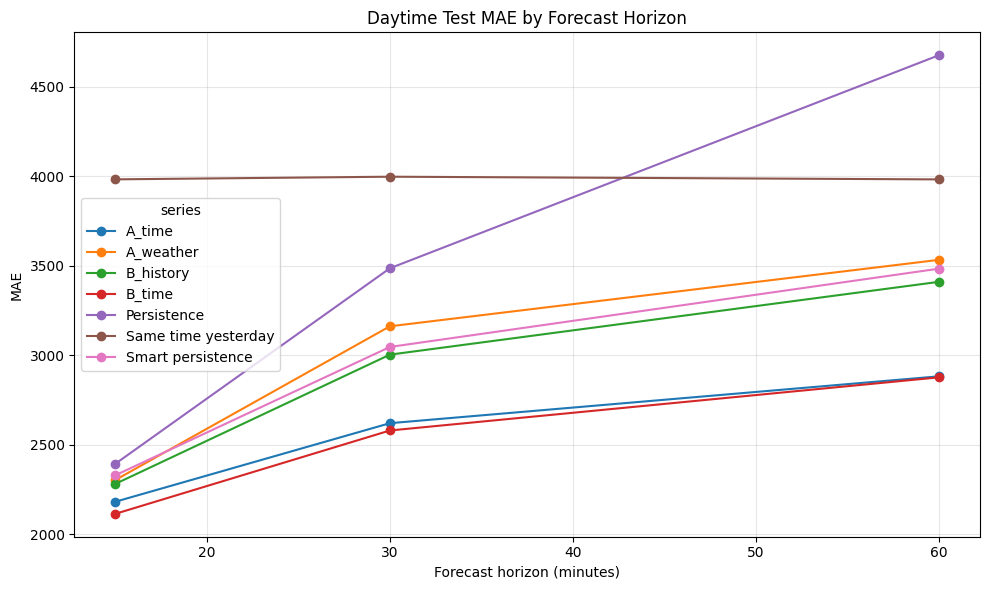

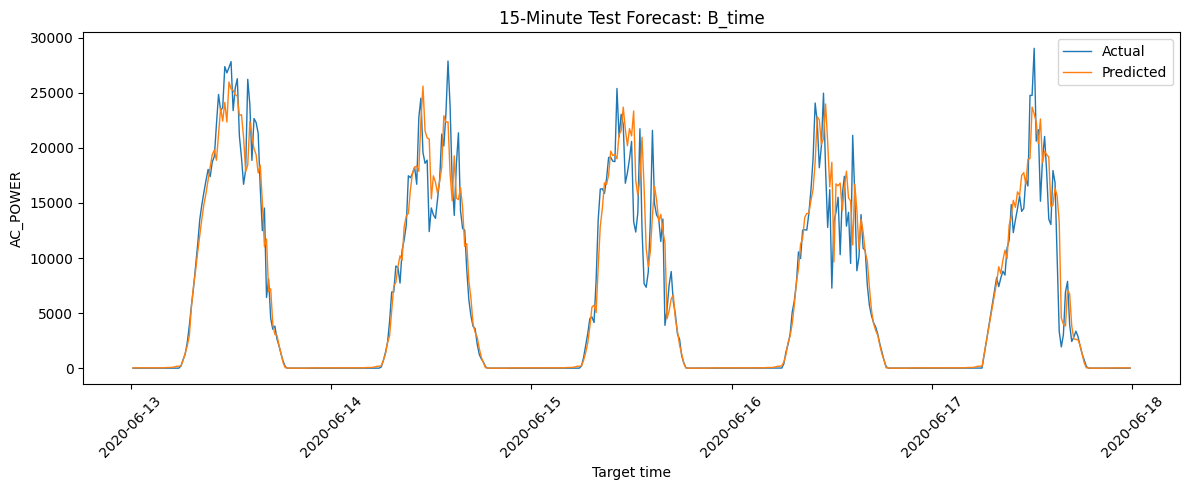

,feature,importance_mean,importance_std
2,MODULE_TEMPERATURE,33.584,26.206
5,AC_POWER_lag3,49.373,29.107
3,AC_POWER_lag1,65.451,28.074
4,AC_POWER_lag2,78.753,61.345
1,AMBIENT_TEMPERATURE,199.716,33.822
0,IRRADIATION,5282.462,241.146


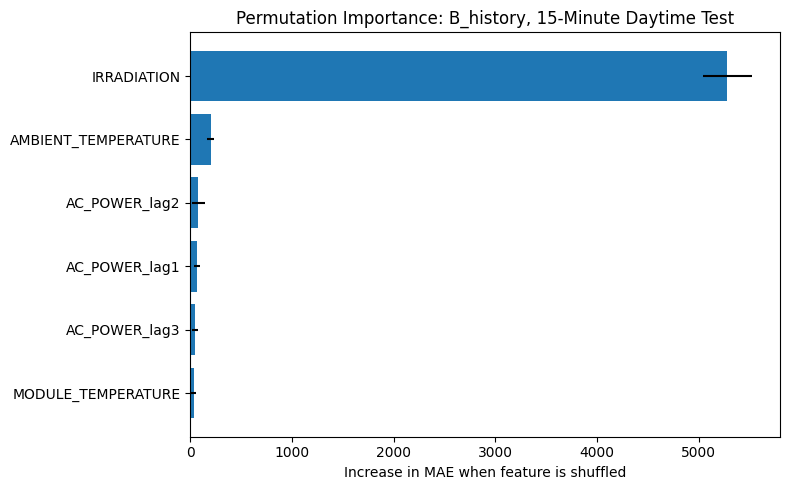

Plots and feature-importance table saved in: /content/drive/MyDrive/Project2_SolarPV/results


In [31]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

results_folder = folder / "results"
results_folder.mkdir(exist_ok=True)

# 1. Test daytime MAE by horizon: ML feature sets and baselines.
ml_plot = test_results[test_results["period"] == "daytime"].copy()
ml_plot["series"] = ml_plot["feature_set"]

baseline_plot = baseline_results[
    baseline_results["period"] == "daytime"
].copy()
baseline_plot["series"] = baseline_plot["baseline"]

plot_data = pd.concat(
    [
        ml_plot[["horizon_minutes", "series", "MAE"]],
        baseline_plot[["horizon_minutes", "series", "MAE"]],
    ],
    ignore_index=True
)

plot_table = plot_data.pivot(
    index="horizon_minutes",
    columns="series",
    values="MAE"
)

ax = plot_table.plot(marker="o", figsize=(10, 6))
ax.set_title("Daytime Test MAE by Forecast Horizon")
ax.set_xlabel("Forecast horizon (minutes)")
ax.set_ylabel("MAE")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(results_folder / "horizon_comparison.png", dpi=150)
plt.show()


# 2. Actual versus predicted for B_time at the 15-minute horizon.
h = 1
feature_name = "B_time"

_, target_time, actual, predicted = test_predictions[(h, feature_name)]

actual_predicted = pd.DataFrame({
    "TARGET_TIME": pd.to_datetime(target_time),
    "actual": np.asarray(actual),
    "predicted": np.asarray(predicted),
}).sort_values("TARGET_TIME")

plt.figure(figsize=(12, 5))
plt.plot(
    actual_predicted["TARGET_TIME"],
    actual_predicted["actual"],
    label="Actual",
    linewidth=1
)
plt.plot(
    actual_predicted["TARGET_TIME"],
    actual_predicted["predicted"],
    label="Predicted",
    linewidth=1
)
plt.title("15-Minute Test Forecast: B_time")
plt.xlabel("Target time")
plt.ylabel("AC_POWER")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(results_folder / "actual_vs_predicted_h1.png", dpi=150)
plt.show()


# 3. Permutation importance for B_history at the 15-minute horizon.
h = 1
feature_name = "B_history"
features = feature_sets[feature_name]

choice = best_by_feature_set[
    (best_by_feature_set["horizon_steps"] == h)
    & (best_by_feature_set["feature_set"] == feature_name)
].iloc[0]

model = make_models()[choice["model"]]

df_h1 = data[h]
train_val = df_h1[df_h1["SPLIT"].isin(["train", "val"])]
test = df_h1[df_h1["SPLIT"] == "test"].copy()

target_hour = test["TARGET_TIME"].dt.hour
test_daytime = test[(target_hour >= 6) & (target_hour < 18)]

model.fit(train_val[features], train_val["TARGET"])

importance = permutation_importance(
    model,
    test_daytime[features],
    test_daytime["TARGET"],
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42
)

importance_table = pd.DataFrame({
    "feature": features,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std,
}).sort_values("importance_mean", ascending=True)

display(importance_table.round(3))

plt.figure(figsize=(8, 5))
plt.barh(
    importance_table["feature"],
    importance_table["importance_mean"],
    xerr=importance_table["importance_std"]
)
plt.title("Permutation Importance: B_history, 15-Minute Daytime Test")
plt.xlabel("Increase in MAE when feature is shuffled")
plt.tight_layout()
plt.savefig(results_folder / "feature_importance_B_h1.png", dpi=150)
plt.show()

importance_table.to_csv(
    results_folder / "feature_importance_B_h1.csv",
    index=False
)

print("Plots and feature-importance table saved in:", results_folder)

In [32]:
for path in sorted(results_folder.iterdir()):
    print(path.name)

actual_vs_predicted_h1.png
feature_importance_B_h1.csv
feature_importance_B_h1.png
horizon_comparison.png
